# Telco customer churn: EDA and model comparison

Question: which account patterns show up among customers who leave, and does gradient boosting beat a logistic regression baseline when both use the same preprocessing and SMOTE?

The table is the IBM Telco Customer Churn extract: 7,043 customers, one row per account. `Churn = Yes` is the positive class. The training code lives in the `churn` package so this notebook and `python -m churn.train` share one pipeline.


In [1]:
from pathlib import Path
import sys

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from churn.config import METRICS_PATH, NUMERIC_FEATURES
from churn.data import load_raw, prepare_dataset
from churn.pipeline import (
    build_pipeline,
    feature_importance_frame,
    logistic_coefficient_frame,
)
from churn.predict import positive_probabilities
from churn.train import run_experiment

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)


## Load and inspect

`customerID` is an identifier, so it stays out of the model matrix. `TotalCharges` arrives as text because eleven tenure-0 accounts have a blank total. Cleaning turns those blanks into 0. They are new accounts, so the total really is zero.


In [2]:
raw = load_raw()
features, target = prepare_dataset(raw)
eda = features.copy()
eda["Churn"] = target.map({1: "Yes", 0: "No"})

print(f"{len(raw):,} rows, {raw.shape[1]} raw columns, {features.shape[1]} model features")
print("Churn counts:")
print(eda["Churn"].value_counts().to_string())
print(f"Churn rate: {(eda['Churn'] == 'Yes').mean():.1%}")
eda.head()


7,043 rows, 21 raw columns, 19 model features
Churn counts:
Churn
No     5174
Yes    1869
Churn rate: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Class balance and data quality

Stay customers outnumber churn customers by about three to one. Accuracy would look strong for a model that never predicts churn, so the comparison below uses precision, recall, F1, and ROC-AUC on the churn class. SMOTE rebalances training folds only.


Blank TotalCharges in the raw file: 11
Missing TotalCharges after cleaning: 0
Missing values in the model matrix:
none


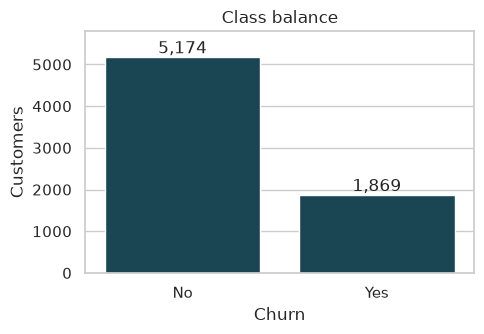

In [3]:
blank_totals = raw["TotalCharges"].astype(str).str.strip().eq("").sum()
print(f"Blank TotalCharges in the raw file: {int(blank_totals)}")
print(f"Missing TotalCharges after cleaning: {int(features['TotalCharges'].isna().sum())}")
print("Missing values in the model matrix:")
missing = features.isna().sum()
missing = missing[missing > 0]
print(missing.to_string() if len(missing) else "none")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts = eda["Churn"].value_counts().reindex(["No", "Yes"])
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#0f4c5c")
ax.set_xlabel("Churn")
ax.set_ylabel("Customers")
ax.set_title("Class balance")
ax.set_ylim(0, counts.max() * 1.12)
for index, value in enumerate(counts.values):
    ax.text(index, value, f"{int(value):,}", ha="center", va="bottom")
fig.tight_layout()
plt.show()


## Numeric distributions

Tenure, monthly charges, and total charges are the numeric inputs. The boxes compare customers who stay with customers who leave.


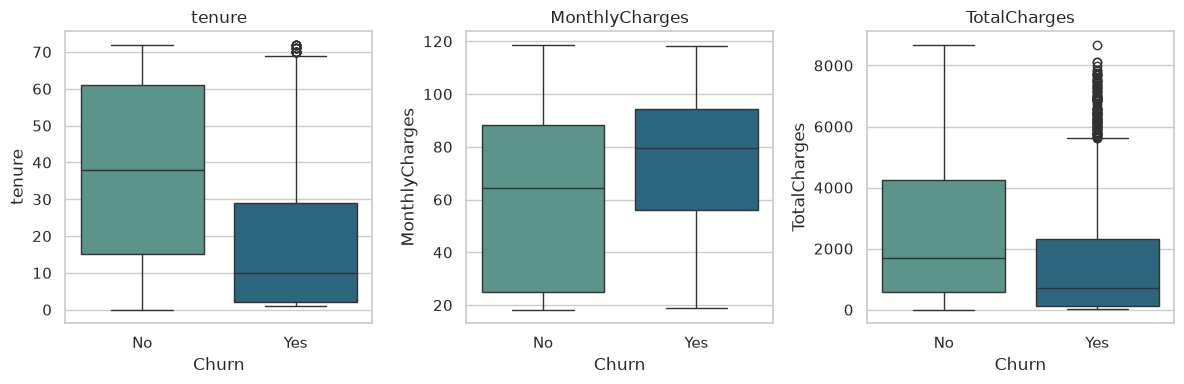

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0           64.43       1679.52
Yes      10.0           79.65        703.55


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, column in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=eda, x="Churn", y=column, hue="Churn", ax=ax, palette="crest", legend=False)
    ax.set_title(column)
fig.tight_layout()
plt.show()

print(eda.groupby("Churn")[list(NUMERIC_FEATURES)].median().round(2))


## Where churn concentrates

The bars are the share of customers who churn inside each level. Contract length, internet type, payment method, and tech support are the comparisons most useful for a retention offer.


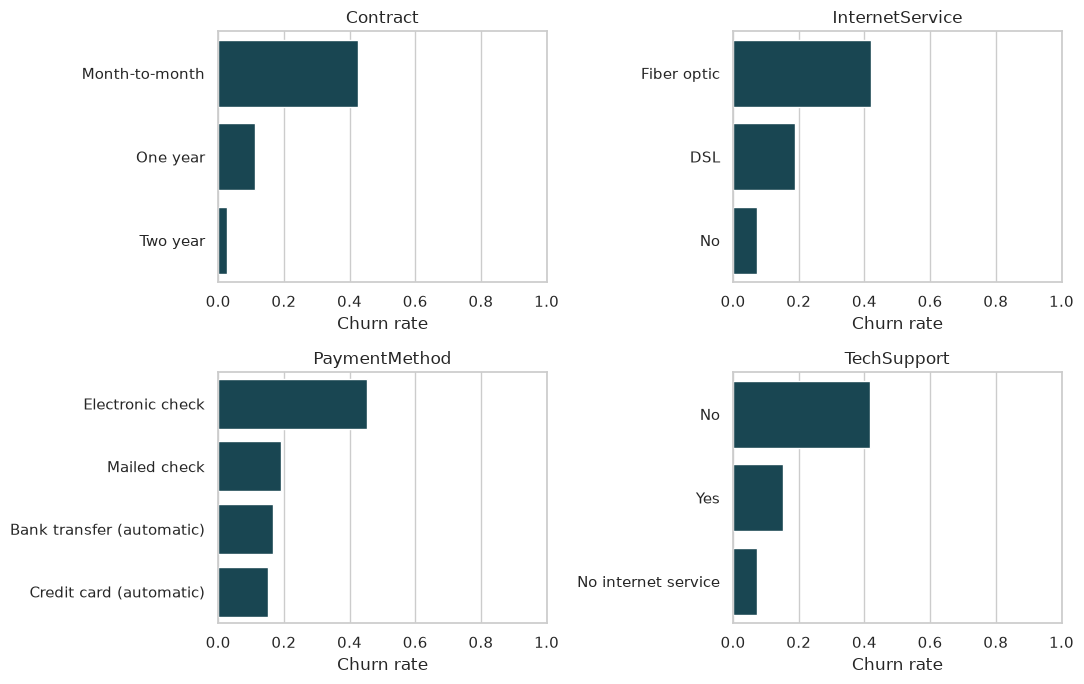

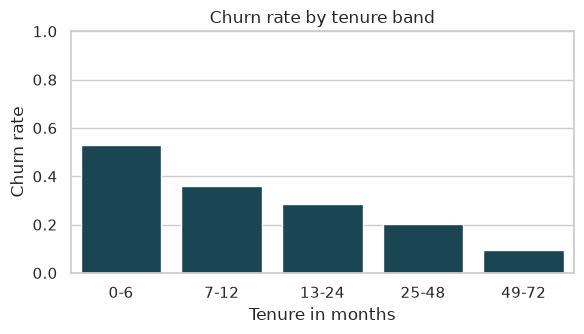

In [5]:
def churn_rate(frame, column):
    scored = frame.assign(_churn=(frame["Churn"] == "Yes").astype(float))
    return scored.groupby(column, observed=True)["_churn"].mean().sort_values(ascending=False)


rate_columns = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column in zip(axes.ravel(), rate_columns):
    rates = churn_rate(eda, column)
    sns.barplot(x=rates.values, y=rates.index.astype(str), ax=ax, color="#0f4c5c")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Churn rate")
    ax.set_ylabel("")
    ax.set_title(column)
fig.tight_layout()
plt.show()

eda["tenure_bin"] = pd.cut(
    eda["tenure"],
    bins=[-0.1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
tenure_rates = churn_rate(eda, "tenure_bin")
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=tenure_rates.index.astype(str), y=tenure_rates.values, ax=ax, color="#0f4c5c")
ax.set_ylim(0, 1)
ax.set_xlabel("Tenure in months")
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by tenure band")
fig.tight_layout()
plt.show()


In [6]:
overall = (eda["Churn"] == "Yes").mean()
print(f"Overall churn rate: {overall:.1%}")
for column in rate_columns:
    rates = churn_rate(eda, column)
    print(f"{column}: highest is {rates.index[0]} at {rates.iloc[0]:.1%}")
print("Churn rate by tenure band, shortest accounts first:")
print(tenure_rates.sort_index().map(lambda value: f"{value:.1%}").to_string())


Overall churn rate: 26.5%
Contract: highest is Month-to-month at 42.7%
InternetService: highest is Fiber optic at 41.9%
PaymentMethod: highest is Electronic check at 45.3%
TechSupport: highest is No at 41.6%
Churn rate by tenure band, shortest accounts first:
tenure_bin
0-6      52.9%
7-12     35.9%
13-24    28.7%
25-48    20.4%
49-72     9.5%


## Correlation

Total charges move with tenure, which is expected because the total is roughly the monthly price times months on the book. Churn itself lines up more with a short tenure than with a large total.


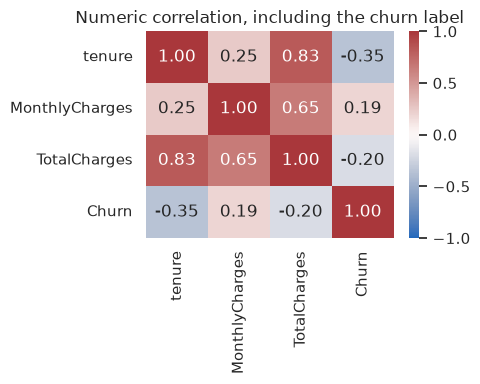

In [7]:
corr = eda[list(NUMERIC_FEATURES)].assign(Churn=target).corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Numeric correlation, including the churn label")
fig.tight_layout()
plt.show()


## Shared model pipeline

Both candidates use one pipeline:

1. Median-impute and standard-scale the numeric columns.
2. Most-frequent-impute and one-hot encode the categorical columns, including `SeniorCitizen`. Encoding is dense, and unseen levels become zeros.
3. SMOTE balances the training labels after that encoding.
4. Fit logistic regression or gradient boosting.

SMOTE sits in an `imblearn` pipeline, so it runs inside `fit` only. Each cross-validation fold resamples its own training rows. The holdout split and the API score the original class mix.

The split is stratified 80/20 with `random_state=42`. Five-fold stratified cross-validation on the training split chooses the saved model by mean F1. Mean ROC-AUC breaks a tie. The holdout metrics are reported once and are not used to pick the winner.


In [8]:
import inspect

print(inspect.getsource(build_pipeline))
print("Logistic pipeline steps:", list(build_pipeline("logistic_regression").named_steps))


def build_pipeline(model_name: str) -> ImbPipeline:
    """Stack preprocessing, SMOTE, and a classifier.

    imblearn's Pipeline runs the sampler during fit only, so validation rows
    and live scoring keep the original class balance.
    """
    return ImbPipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            ("smote", SMOTE(**SMOTE_PARAMS)),
            ("classifier", build_estimator(model_name)),
        ]
    )

Logistic pipeline steps: ['preprocessor', 'smote', 'classifier']


## Fit and compare

The next cell refits both models the same way `python -m churn.train` does. Gradient boosting with 200 trees and five folds takes about a minute.


In [9]:
result = run_experiment(raw)
report = result["report"]
print(f"Best model by mean CV F1: {result['best_name']}")
print(f"Train churn rate: {report['class_balance']['train']['churn_rate']:.1%}")
print(f"Test churn rate: {report['class_balance']['test']['churn_rate']:.1%}")

rows = []
for name, metrics in report["models"].items():
    for split in ("cv", "holdout"):
        block = metrics[split]
        row = {"model": name, "split": split}
        for metric in ("precision", "recall", "f1", "roc_auc"):
            raw_value = block[metric]
            row[metric] = raw_value["mean"] if isinstance(raw_value, dict) else raw_value
        rows.append(row)
comparison = pd.DataFrame(rows)
comparison.round(4)


Best model by mean CV F1: gradient_boosting
Train churn rate: 26.5%
Test churn rate: 26.5%


,model,split,precision,recall,f1,roc_auc
0,logistic_regression,cv,0.5256,0.7880,0.6303,0.8448
1,logistic_regression,holdout,0.5034,0.7968,0.6170,0.8399
2,gradient_boosting,cv,0.5905,0.6809,0.6324,0.8466
3,gradient_boosting,holdout,0.5644,0.6791,0.6165,0.8428


## Holdout ROC and confusion matrices

ROC-AUC uses the churn probability. The confusion matrices use the 0.50 cutoff that produces the precision, recall, and F1 above. Rows are the true Stay (0) and Churn (1) labels.


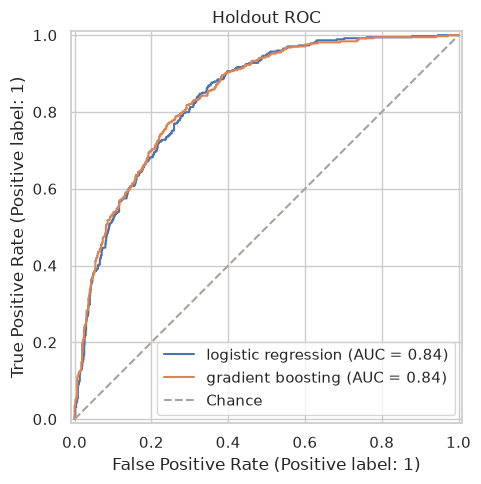

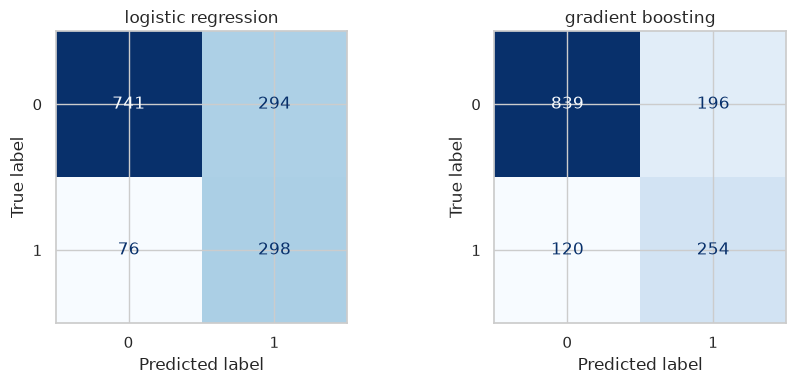

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
for name, pipeline in result["pipelines"].items():
    RocCurveDisplay.from_predictions(
        result["y_test"],
        positive_probabilities(pipeline, result["X_test"]),
        name=name.replace("_", " "),
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="#a8a29e", label="Chance")
ax.set_title("Holdout ROC")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, pipeline) in zip(axes, result["pipelines"].items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline,
        result["X_test"],
        result["y_test"],
        ax=ax,
        colorbar=False,
        cmap="Blues",
    )
    ax.set_title(name.replace("_", " "))
fig.tight_layout()
plt.show()


## What SMOTE changes on the training split

The counts below fit the preprocessor and SMOTE on the training split only, as an illustration. The models above do the same step inside each training fold. The holdout labels are not resampled.


In [11]:
from imblearn.over_sampling import SMOTE
from churn.pipeline import build_preprocessor

transformed = build_preprocessor().fit_transform(result["X_train"], result["y_train"])
_resampled_x, resampled_y = SMOTE(random_state=42).fit_resample(transformed, result["y_train"])
before = result["y_train"].value_counts().sort_index()
after = pd.Series(resampled_y).value_counts().sort_index()
balance = pd.DataFrame({"before_smote": before, "after_smote": after})
balance.index = balance.index.map({0: "Stay", 1: "Churn"})
balance


,before_smote,after_smote
Churn,,
Stay,4139,4139
Churn,1495,4139


## What the models use

Gradient boosting importances and the largest logistic coefficients are on the encoded columns. Names with the `cat__` prefix are one-hot levels. A positive logistic coefficient pushes the log-odds toward churn.


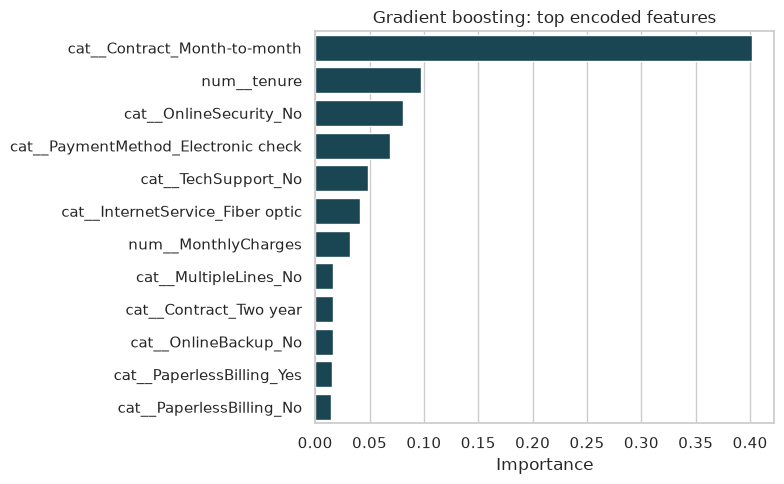

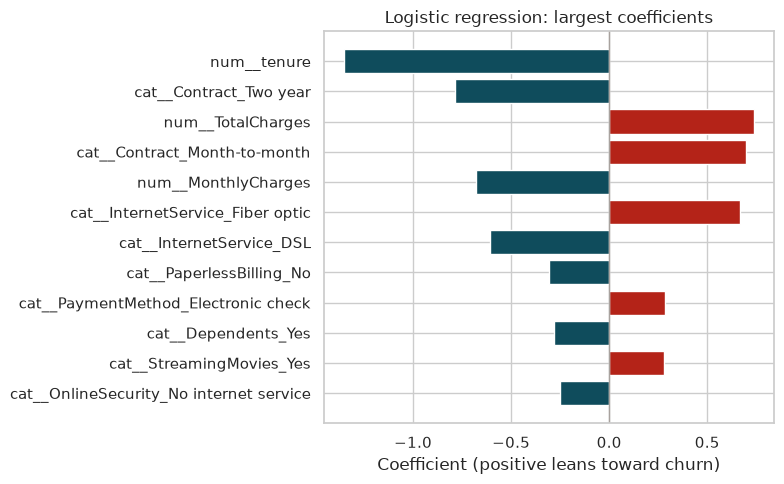

In [12]:
importances = feature_importance_frame(result["pipelines"]["gradient_boosting"]).head(12)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=importances, x="importance", y="feature", ax=ax, color="#0f4c5c")
ax.set_title("Gradient boosting: top encoded features")
ax.set_xlabel("Importance")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

coefficients = logistic_coefficient_frame(result["pipelines"]["logistic_regression"]).head(12)
colors = ["#b42318" if value > 0 else "#0f4c5c" for value in coefficients["coefficient"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coefficients["feature"], coefficients["coefficient"], color=colors)
ax.invert_yaxis()
ax.axvline(0, color="#a8a29e", linewidth=1)
ax.set_title("Logistic regression: largest coefficients")
ax.set_xlabel("Coefficient (positive leans toward churn)")
fig.tight_layout()
plt.show()


## Conclusion

The cell below states the selected model and its holdout precision, recall, F1, and ROC-AUC from this run. When `models/metrics.json` is present, the recomputed holdout numbers are checked against the file written by `python -m churn.train`.


In [13]:
import json

best = result["best_name"]
holdout = report["models"][best]["holdout"]
print(f"Selected model: {best}")
print(
    "Holdout precision {precision:.3f}, recall {recall:.3f}, "
    "F1 {f1:.3f}, ROC-AUC {roc_auc:.3f}.".format(**holdout)
)
print("Risk tiers on the served probability: Low under 0.30, Medium under 0.60, High from 0.60.")
print("The Churn/Stay label uses a 0.50 cutoff. Tiers are an outreach priority, separate from that label.")

if METRICS_PATH.exists():
    saved = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
    assert saved["best_model"] == best
    for name, metrics in report["models"].items():
        for metric, value in metrics["holdout"].items():
            stored = saved["models"][name]["holdout"][metric]
            if abs(round(value, 6) - stored) > 1e-6:
                raise AssertionError(f"{name} {metric}: notebook {value} vs saved {stored}")
    print("Recomputed holdout metrics match models/metrics.json.")
else:
    print("models/metrics.json is absent. Run python -m churn.train to save the served pipeline.")


Selected model: gradient_boosting
Holdout precision 0.564, recall 0.679, F1 0.617, ROC-AUC 0.843.
Risk tiers on the served probability: Low under 0.30, Medium under 0.60, High from 0.60.
The Churn/Stay label uses a 0.50 cutoff. Tiers are an outreach priority, separate from that label.
Recomputed holdout metrics match models/metrics.json.
